In [27]:
import os
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
from torchvision import transforms

In [20]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [32]:
path = r"file _location"

# Load images
def load_images(filename):

    file_path = os.path.join(path, filename)

    with open(file_path, "rb") as f:
        data = np.fromfile(f, dtype=np.uint8)

    images = data[16:].reshape(-1, 28, 28)

    return images


# Load labels
def load_labels(filename):

    file_path = os.path.join(path, filename)

    with open(file_path, "rb") as f:
        data = np.fromfile(f, dtype=np.uint8)

    labels = data[8:]

    return labels


# Training data
X_train = load_images("train-images-idx3-ubyte")
y_train = load_labels("train-labels-idx1-ubyte")

# Testing data
X_test = load_images("t10k-images-idx3-ubyte")
y_test = load_labels("t10k-labels-idx1-ubyte")


# Convert to tensors
X_train = torch.tensor(X_train, dtype=torch.float32) / 255.0
y_train = torch.tensor(y_train, dtype=torch.long)

X_test = torch.tensor(X_test, dtype=torch.float32) / 255.0
y_test = torch.tensor(y_test, dtype=torch.long)


# Add channel dimension
X_train = X_train.unsqueeze(1)
X_test = X_test.unsqueeze(1)


# Create datasets
train_dataset = TensorDataset(X_train, y_train)
test_dataset = TensorDataset(X_test, y_test)


# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))
print("Dataset loaded successfully!")

Training samples: 60000
Testing samples: 10000
Dataset loaded successfully!


In [33]:
augmentation = transforms.RandomRotation(10)

In [34]:
class CNN(nn.Module):

    def __init__(self):
        super(CNN, self).__init__()

        self.conv = nn.Sequential(

            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.fc = nn.Sequential(

            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):

        x = self.conv(x)
        x = self.fc(x)

        return x


cnn_model = CNN().to(device)

print(cnn_model)

CNN(
  (conv): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [35]:
class MLP(nn.Module):

    def __init__(self):
        super(MLP, self).__init__()

        self.network = nn.Sequential(

            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 10)
        )

    def forward(self, x):

        return self.network(x)


mlp_model = MLP().to(device)

print(mlp_model)

MLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [36]:
def train_model(model, train_loader, test_loader, epochs=5):

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    train_losses = []
    test_accuracies = []

    for epoch in range(epochs):

        model.train()
        running_loss = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            # Apply augmentation only during training
            if isinstance(model, CNN):
                images = augmentation(images)

            outputs = model(images)

            loss = criterion(outputs, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        avg_loss = running_loss / len(train_loader)
        train_losses.append(avg_loss)

        # Testing
        model.eval()

        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in test_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        accuracy = 100 * correct / total

        test_accuracies.append(accuracy)

        print(
            f"Epoch [{epoch+1}/{epochs}], "
            f"Loss: {avg_loss:.4f}, "
            f"Accuracy: {accuracy:.2f}%"
        )

    return train_losses, test_accuracies

In [37]:
print("Training CNN Model")

cnn_losses, cnn_accuracies = train_model(
    cnn_model,
    train_loader,
    test_loader,
    epochs=5
)

Training CNN Model
Epoch [1/5], Loss: 0.3036, Accuracy: 97.81%
Epoch [2/5], Loss: 0.0827, Accuracy: 98.53%
Epoch [3/5], Loss: 0.0623, Accuracy: 98.85%
Epoch [4/5], Loss: 0.0509, Accuracy: 99.01%
Epoch [5/5], Loss: 0.0408, Accuracy: 99.04%


In [38]:
print("Training MLP Model")

mlp_losses, mlp_accuracies = train_model(
    mlp_model,
    train_loader,
    test_loader,
    epochs=5
)

Training MLP Model
Epoch [1/5], Loss: 0.4145, Accuracy: 93.58%
Epoch [2/5], Loss: 0.1783, Accuracy: 95.73%
Epoch [3/5], Loss: 0.1271, Accuracy: 96.55%
Epoch [4/5], Loss: 0.0962, Accuracy: 96.94%
Epoch [5/5], Loss: 0.0766, Accuracy: 96.75%


In [39]:
print("CNN Accuracy:", cnn_accuracies[-1], "%")
print("MLP Accuracy:", mlp_accuracies[-1], "%")

CNN Accuracy: 99.04 %
MLP Accuracy: 96.75 %


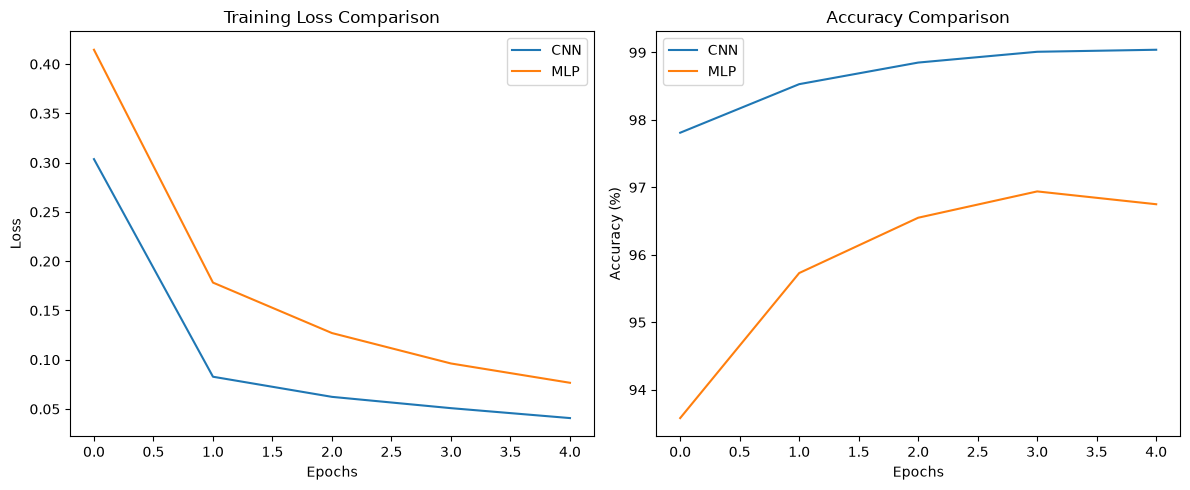

In [40]:
plt.figure(figsize=(12, 5))

# Loss comparison
plt.subplot(1, 2, 1)

plt.plot(cnn_losses, label="CNN")
plt.plot(mlp_losses, label="MLP")

plt.title("Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()


# Accuracy comparison
plt.subplot(1, 2, 2)

plt.plot(cnn_accuracies, label="CNN")
plt.plot(mlp_accuracies, label="MLP")

plt.title("Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.legend()

plt.tight_layout()
plt.show()